In [1]:
# importing libraries
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, cross_val_predict, StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import fbeta_score, average_precision_score, precision_score, recall_score, confusion_matrix, precision_recall_curve


In [2]:
# Loading cleaned training data
notebook_path = Path.cwd()
project_path = notebook_path.parent
data_path = project_path / "data" / "processed" / "cleaned_train.parquet"

df = pd.read_parquet(data_path)

Now we are going to test VIF (Variance Inflation Factor) in our features to make sure we are safe against multicolinearity (even though it's just dangerous for linear models and we use tree based models as well, and also we are not going to interpret the coefficients as a medical proof of what factors are more important for hearing loss, beacuase the main goal of this project is prediction. We just run it to see which features are largely explained by other features and it's a good thing to know).


In [3]:
x = df.drop(columns= 'hl_presence')
y = df['hl_presence']
vif_data = pd.DataFrame()
vif_data['feature'] = x.columns
vif_values = []
for i in range(len(x.columns)):
  score = variance_inflation_factor(x.values, i)
  vif_values.append(score)

# Assign the finished list to your table
vif_data['vif'] = vif_values
vif_data


,feature,vif
0,sex,1.206223
1,age,1.497179
2,education,1.047324
3,loud_noise,2.306808
4,very_loud_noise,2.260485
5,blood_pressure,1.190223
6,diabetes,1.104472
7,gun_risk,1.115277
8,lead_log,1.419580
9,cadmium_log,1.144139


Based on the results, all of the features show low VIF scores (<3), which shows they are mostly independent from each other and none of the features are driven by others (at least not significantly). We can feel safe for multicolinearity and even take a more serious look toward our coefficients (even though we still can not conclude for example lead causes hearing loss as this is not a controlled study. we can simply say lead is a statistically strong predictor in this dataset)

Now before moving one to the model selection, I want to make sure keeping the lead/cadmium columns is a good idea or not because more than half the data is imputed (52%). For this, I will train 2 models (one linear and one tree based) both with and without lead/cadmium columns to see how they perform.Then I choose to keep them or not.

In [4]:
skf = StratifiedKFold(n_splits = 5, shuffle= True, random_state= 42)

# Columns with and without lead/cadmium
cols_with = x.columns.tolist()
cols_without = [c for c in cols_with if c not in ['lead_log', 'cadmium_log']]

# Models I want to use for screening these 2 columns
models = [
    ('logreg', LogisticRegression(class_weight= 'balanced', max_iter= 1000)),
    ('rf', RandomForestClassifier(class_weight= 'balanced', random_state= 42))
]

feature_sets = [
    ('with lead/cadmium', cols_with),
    ('without lead/cadmium', cols_without)
]

# Now we iterate through each model with each dataset (2 models with 2 datasets outputing 4 scores (PR-AUC)):
for model_name, model in models:
    for label, cols in feature_sets:

        # We use a pipline to always scale then do the modeling in each cycle in k-fold to prevent data leakage:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('model', model)
        ])

        # Now calculating the scores:
        scores = cross_val_score (
            pipe, x[cols], y, cv = skf, scoring= 'average_precision' # average_precision is practically same as PR-AUC
        )

        print(f"{model_name} | {label} | PR-AUC = {round(scores.mean(), 3)} (+/- {round(scores.std(), 3)})")


logreg | with lead/cadmium | PR-AUC = 0.474 (+/- 0.037)
logreg | without lead/cadmium | PR-AUC = 0.475 (+/- 0.029)
rf | with lead/cadmium | PR-AUC = 0.399 (+/- 0.024)
rf | without lead/cadmium | PR-AUC = 0.387 (+/- 0.018)


As you can see, both LogisticRegression and RandomForest performances did no improve with these 2 columns. Considering the fact that 52% of their data were imputed, I belive they provide no value for our performance, so I decide to drop them.

In [5]:
x = x.drop(columns= ['lead_log', 'cadmium_log'])
x.columns

Index(['sex', 'age', 'education', 'loud_noise', 'very_loud_noise',
       'blood_pressure', 'diabetes', 'gun_risk'],
      dtype='str')

Now we move forward to the next phase: Comparing all model architectures with PR-AUC 

Models I want to try : Logistic regression, Random Forest, XGB Classifier, Naive Bayes and KNN.

I want to note that even though KNN doesn't produce any feature importance and it can't be optimized for imbalanced data as good as LR or RF, it's still worth a shot to see how it performs. Also for Naive Bayes, I know that this model assumes the data has a normal bell distribution and that is not the case with most features in my data, but I still want to include it as a simple baseline.

In [6]:
models = [
    ('logreg', LogisticRegression(class_weight= 'balanced', max_iter= 1000, random_state= 42)),
    ('rf', RandomForestClassifier(class_weight= 'balanced', random_state= 42)),
    ('xgb', XGBClassifier(
        scale_pos_weight= (y == 0).sum() / (y == 1).sum(), # equvalent of class_weight = 'balanced' for XGBOOST
        eval_metric = 'logloss', random_state = 42
    )),
    ('knn', KNeighborsClassifier(weights= 'distance')), # closer neighbors count more than the far ones which slightly helps the imbalance 
    ('nb', GaussianNB(priors= [0.5, 0.5])) # for overriding class imbalance
]


for model_name, model in models:

    pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('model', model)
            ])

    scores = cross_val_score(pipe, x, y, cv = skf, scoring= 'average_precision')
    print(f"{model_name} | PR-AUC = {round(scores.mean(), 3)} (+/- {round(scores.std(), 3)})")

logreg | PR-AUC = 0.475 (+/- 0.029)
rf | PR-AUC = 0.387 (+/- 0.018)
xgb | PR-AUC = 0.389 (+/- 0.039)
knn | PR-AUC = 0.351 (+/- 0.035)
nb | PR-AUC = 0.403 (+/- 0.029)


As we can see LR has produced the largest score for PR-AUC, followed by NB, and at the end RF and XGB are closely third and we have KNN at last. Based on our EDA, our strongest predictor was age with rank-biserial nearly 0.6 that was above everything else and it acted linearly. In addition to that, most other ordinal features like exposure to noise were monotonic and acted linearly too (more noise -> more likely to have HL, similar to age). This is a very ideal setup for LR to predict.

Based on the mostly linear pattern seen in our EDA, we can understand why tree models didn't work as good as LR. Tree models work better with non-linear patterns and features that interact with each other. This dataset wasn't ideal for them and there were not that many features that could be broken down in to 2 or more nodes in the trees and predict the labels.

Aside from these 3, NB performed better than expected, even though most of our data is not normally distributed. And at last, I believe the main reason KNN performed very poorly is that, it's not designed for this much imbalance in the data and weights= 'distance' didn't help that much.

For the next phase we will be using Logistic Regression and will tune its hyperparameters.

In [7]:
pipe= Pipeline ([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight= 'balanced', max_iter= 1000, random_state= 42, solver='saga'))
])

param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100], # Smaller values specify stronger regularization (penalizing complex weights to stop overfitting)
    'model__l1_ratio': [0.0, 1.0] # 'l2' shrinks coefficients smoothly, 'l1' can drive weak feature coefficients to zero (l1_ratio = 1.0 means l1 and 0 means l2)
}

grid = GridSearchCV(
    estimator= pipe,
    param_grid= param_grid,
    cv = skf,
    scoring= 'average_precision',
    n_jobs = -1
)

grid.fit(x, y)

print('Best Parameters: ', grid.best_params_)
print('Best PR-AUC: ', grid.best_score_)

best_pipeline = grid.best_estimator_

Best Parameters:  {'model__C': 0.1, 'model__l1_ratio': 1.0}
Best PR-AUC:  0.4754325598204258


Now that we have found the best parameters, we can move on to the next phase and find the best threshold for our model.
We will use out-of-fold (OOF) prediction to find the best threshold to prevent from data leakage.

In [8]:
# this will use our best parameters to generate a probability for every row.
oof_probs= cross_val_predict(
    best_pipeline,
    x,
    y,
    cv = skf,
    method = 'predict_proba', # this is to output a probability not 0 or 1
    n_jobs = -1
)[:, 1] # this is to only extract the probability of positive case (with HL)

# An array of 99 thresolds from 0.01 to 0.09
thresholds = np.arange(0.01, 1, 0.01)

# Here we will be converting these probabilities into a binary prediction (0,1) based on the threshold (which increases from 0.01 to 0.99)
# and generating an f2 score to compare these threshold and find the best one. 
# (we use f2 as we prioritize recall over precision, I believe losing a HL case is much more costly than having a false alarm)

f2_scores = [fbeta_score(y, oof_probs>= t, beta= 2) for t in thresholds]

best_threshold = thresholds[np.argmax(f2_scores)]

print(f" Best threshold = {round(best_threshold, 3)} \n F2 = {round(max(f2_scores), 3)}")

 Best threshold = 0.47 
 F2 = 0.637


Now that we have found the best threshold, we will train the model on our whole training set and then run it on the test set for the first time.

In [9]:
best_pipeline.fit(x, y)

# test data path
test_data_path = project_path / "data" / "processed" / "cleaned_test.parquet"
df_test = pd.read_parquet(test_data_path)

# Removing lead and cadmium from df_test and seperating it into data and label
x_test = df_test.drop(columns=['hl_presence', 'lead_log', 'cadmium_log'])
y_test = df_test['hl_presence']

test_probs = best_pipeline.predict_proba(x_test)[:, 1]
test_preds = np.where(test_probs >= best_threshold, 1, 0)

print("F2:", round(fbeta_score(y_test, test_preds, beta=2),3))
print("PR-AUC:", round(average_precision_score(y_test, test_probs),3))
print("Precision:", round(precision_score(y_test, test_preds), 3))
print("Recall:", round(recall_score(y_test, test_preds), 3))
print("Confusion matrix:\n", confusion_matrix(y_test, test_preds))

F2: 0.602
PR-AUC: 0.454
Precision: 0.329
Recall: 0.759
Confusion matrix:
 [[511 212]
 [ 33 104]]


Final model evaluation:

The tuned logistic regression pipeline (C=0.1, l1_ratio = 1.0, threshold=0.47 selected with OOF F2 optimization) was refit on the full training set and evaluated
on the test set (the first and only time test data was used). The PR-AUC dropped from 0.47 in CV to 0.45 in test set. F2 score dropped from 0.63 in CV to 0.6 in test set as well. This drop is a normal generalization gap and not a sign of overfitting, as we used a leakage safe pipeline structure (imputation, scaling, threshold selection all fit on train only).

My model catches 104 of 137 true HL cases (recall = 76%), at the cost of 212 false alarms. This is consistent with my F2 score to prioritize detecting HL cases over false alarms. I am going to continue evaluating the results further down:

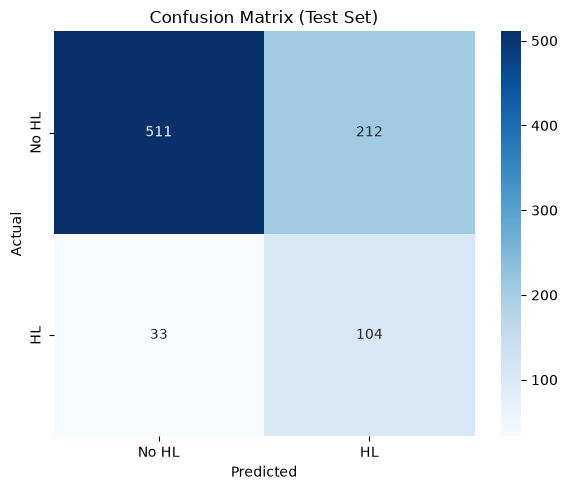

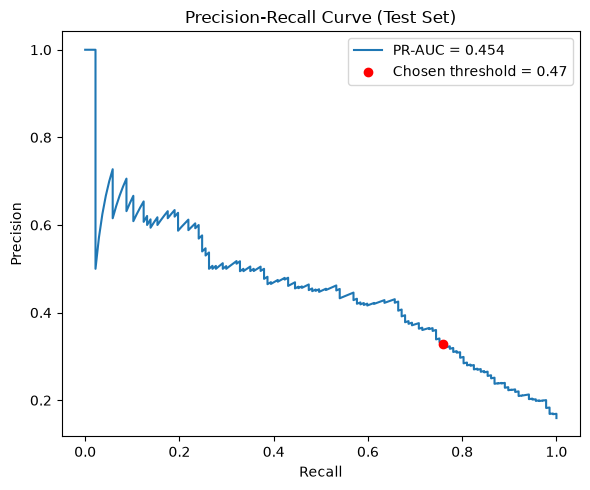

In [13]:
cm = confusion_matrix(y_test, test_preds)
precisions, recalls, pr_thresholds = precision_recall_curve(y_test, test_probs)
ap = average_precision_score(y_test, test_probs)
idx = np.argmin(np.abs(pr_thresholds - best_threshold))

# --- Plot 1: Confusion Matrix ---
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No HL', 'HL'], yticklabels=['No HL', 'HL'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.savefig('../images/model_training_results/Confusion_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Plot 2: Precision-Recall Curve ---
plt.figure(figsize=(6, 5))
plt.plot(recalls, precisions, label=f'PR-AUC = {ap:.3f}')
plt.scatter(recalls[idx], precisions[idx], color='red', zorder=5,
            label=f'Chosen threshold = {best_threshold:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve (Test Set)')
plt.legend()
plt.tight_layout()
plt.savefig('../images/model_training_results/PR_Curve.png', dpi=300, bbox_inches='tight')
plt.show()

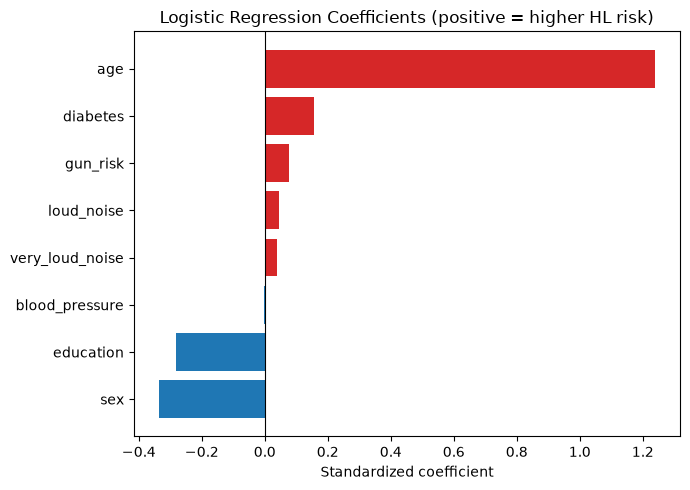

In [14]:
# Now showing the coefficients importance
coefs = pd.Series(
    best_pipeline.named_steps['model'].coef_[0],
    index=x.columns
).sort_values()

plt.figure(figsize=(7, 5))
colors = coefs.apply(lambda v:'#d62728' if v > 0 else '#1f77b4')
plt.barh(coefs.index, coefs.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Standardized coefficient')
plt.title('Logistic Regression Coefficients (positive = higher HL risk)')
plt.tight_layout()
plt.savefig('../images/model_training_results/Coefficients.png', dpi=300, bbox_inches='tight')
plt.show()

Age dominates all other features which is consistent with its rank-biserial of 0.598 in EDA. Presbycusis is the primary driver of hearing loss.
Diabetes, gun_risk, and both noise-exposure features show smaller but positive associations which are also aligned with their bivariate results.

Two results worth noting explicitly:
blood_pressure ≈ 0, despite a moderate effect in EDA (rank-biserial 0.252). This matches the age-confounding concern that I had during the correlation-matrix review (age-BP r=0.38). Once age is in the model, blood pressure's signal appears mostly absorbed by it rather than acting independently.

sex is negative (female → lower predicted risk) and that is a well scientifically proven fact that men are more prone to heasring loss (due to several reasons such as their occupational and recreational activities). Since gun_risk and the noise features are also male-skewed, sex's coefficient may partly be capturing residual effects not fully explained by those features alone.

As noted earlier, these are associations within a cross-sectional predictive model and we can not conclude casual observations from them.